In [1]:
import numpy as np

import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

import tensorflow as tf

np.set_printoptions(precision=3)

In [2]:
data = np.loadtxt('data_w3_ex1.csv', delimiter=',')
x = data[:,0]
y = data[:,1]
print(x.shape)
print(y.shape)

(50,)
(50,)


In [3]:
x = np.expand_dims(x, axis=1)
y = np.expand_dims(y, axis=1)
print(x.shape)
print(y.shape)

(50, 1)
(50, 1)


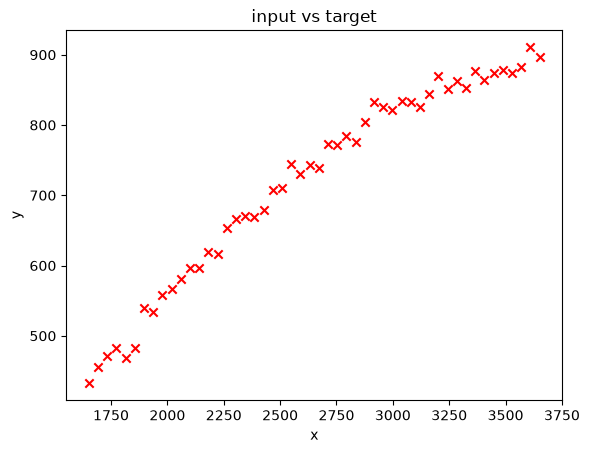

In [4]:
plt.scatter(x, y, marker='x', c='r', label='data points')
plt.xlabel('x')
plt.ylabel('y')
plt.title('input vs target')
plt.show()

In [5]:
x_train, x_, y_train, y_ = train_test_split(x, y, test_size=0.4, random_state=1)

x_cv, x_test, y_cv, y_test = train_test_split(x_, y_, test_size=0.5, random_state=1)

del x_, y_

print(f"x_train.shape: {x_train.shape}")
print(f"x_cv.shape: {x_cv.shape}")
print(f"x_test.shape: {x_test.shape}")
print(f"y_train.shape: {y_train.shape}")
print(f"y_cv.shape: {y_cv.shape}")
print(f"y_test.shape: {y_test.shape}")

x_train.shape: (30, 1)
x_cv.shape: (10, 1)
x_test.shape: (10, 1)
y_train.shape: (30, 1)
y_cv.shape: (10, 1)
y_test.shape: (10, 1)


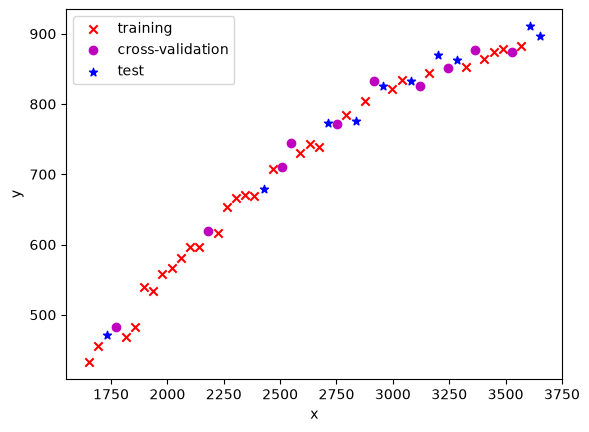

In [6]:
plt.scatter(x_train, y_train, marker='x', c='r', label='training')
plt.scatter(x_cv, y_cv, marker='o', c='m', label='cross-validation')
plt.scatter(x_test, y_test, marker='*', c='b', label='test')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

In [7]:
scaler_linear = StandardScaler()

X_train_scaled = scaler_linear.fit_transform(x_train)

print(f"Computed mean of training set: {scaler_linear.mean_.squeeze():0.2f}")
print(f"Computed standard deviation of training set: {scaler_linear.scale_.squeeze():0.2f}")

Computed mean of training set: 2504.06
Computed standard deviation of training set: 574.85


In [8]:
print(f"min of unscaled training set: {np.min(x_train):0.2f}")
print(f"max of unscaled training set: {np.max(x_train):0.2f}")
print(f"min of scaled training set: {np.min(X_train_scaled):0.2f}")
print(f"max of scaled training set: {np.max(X_train_scaled):0.2f}")

min of unscaled training set: 1651.00
max of unscaled training set: 3569.37
min of scaled training set: -1.48
max of scaled training set: 1.85


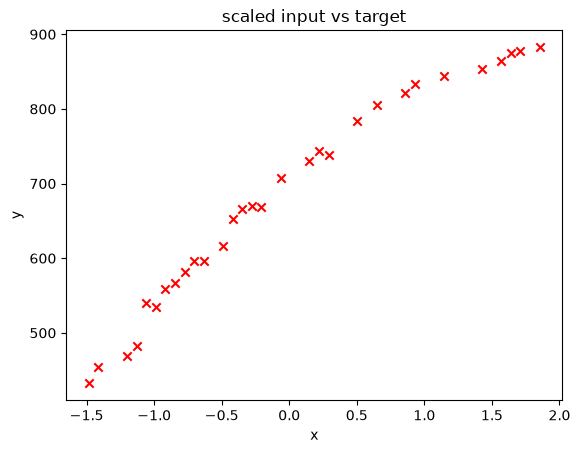

In [9]:
plt.scatter(X_train_scaled, y_train, marker='x', c='r', label='data points')
plt.xlabel('x')
plt.ylabel('y')
plt.title('scaled input vs target')
plt.show()

In [10]:
linear_model = LinearRegression()

linear_model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[136.36]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[681.55]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[5.48]


In [11]:
print(f"linear_model.coef_ (w): {(w := linear_model.coef_.squeeze()):0.2f}")
print(f"linear_model.intercept (b): {(b := linear_model.intercept_.squeeze()):0.2f}")

linear_model.coef_ (w): 136.36
linear_model.intercept (b): 681.55


In [12]:
w, b

(array(136.357), array(681.553))

In [13]:
# so our model equation becomes
print(f"model function: f(x) = {w:0.2f}x + {b:0.2f}")

model function: f(x) = 136.36x + 681.55


In [14]:
x = np.array([[0.5]])
my_yhat = w * x + b
sklearn_yhat = linear_model.predict(x)
print(f"my_yhat: {my_yhat.squeeze()}")
print(f"sklearn_yhat: {sklearn_yhat.squeeze()}")

my_yhat: 749.7319782114757
sklearn_yhat: 749.7319782114757


In [15]:
yhat = linear_model.predict(X_train_scaled)

print(f"training MSE using sklearn: {mean_squared_error(y_train, yhat) / 2}")

total_squared_error = 0
m = len(yhat)
for i in range(m):
    squared_error_i = (yhat[i] - y_train[i]) ** 2
    total_squared_error += squared_error_i
mse = total_squared_error / (2*m)
print(f"training MSE using loop implementation: {mse.squeeze()}")

training MSE using sklearn: 406.19374192533155
training MSE using loop implementation: 406.19374192533155


In [16]:
x_cv_scaled = scaler_linear.transform(x_cv)

yhat = linear_model.predict(x_cv_scaled)

print(f"cross-validation MSE: {mean_squared_error(y_cv, yhat) / 2}")

cross-validation MSE: 551.7789026952216


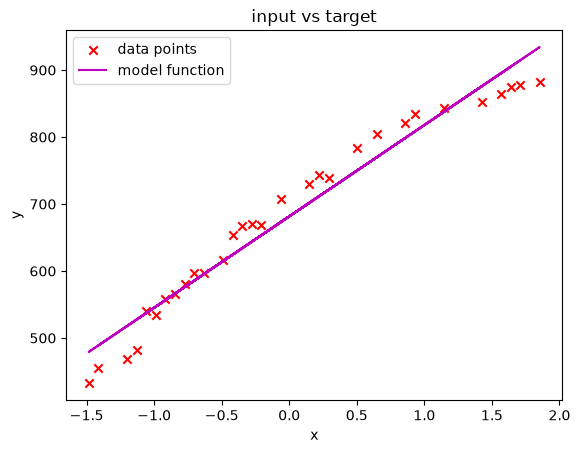

In [17]:
plt.scatter(X_train_scaled, y_train, marker='x', c='r', label='data points')
plt.plot(X_train_scaled, w*X_train_scaled+b, c='m', label='model function')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.title('input vs target')
plt.show()

In [18]:
# so as seen above a straight line is not prefectly fits into our data points
# we have to use some polynomial features to get lines other than straight as well

In [19]:
poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_mapped = poly.fit_transform(x_train)

print(X_train_mapped[:5])

[[3.324e+03 1.105e+07]
 [2.345e+03 5.498e+06]
 [3.488e+03 1.216e+07]
 [2.631e+03 6.920e+06]
 [2.590e+03 6.707e+06]]


In [20]:
scaler_poly = StandardScaler()

X_train_mapped_scaled = scaler_poly.fit_transform(X_train_mapped)

print(X_train_mapped_scaled[:5])

print(X_train_mapped_scaled.shape)

print(np.min(X_train_mapped_scaled, axis=0))
print(np.max(X_train_mapped_scaled, axis=0))

[[ 1.427  1.472]
 [-0.277 -0.365]
 [ 1.711  1.84 ]
 [ 0.22   0.106]
 [ 0.149  0.035]]
(30, 2)
[-1.484 -1.282]
[1.853 2.031]


In [21]:
model = LinearRegression()
model.fit(X_train_mapped_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 2)","[[ 412.94,-277.87]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[681.55]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](2,)","[7.74,0.37]"


In [22]:
print(f"w: {(w:=model.coef_.reshape(-1))}")
print(f"b: {(b:=model.intercept_.squeeze())}")

w: [ 412.943 -277.874]
b: 681.5533349140236


In [23]:
# so our model equation is w1x + w2x^2 + b
print(f"model function: {w[0]:0.3f} x + {w[1]:0.3f} x^2 + {b:0.3f}")

model function: 412.943 x + -277.874 x^2 + 681.553


In [24]:
x = np.array(2500) # input for prediction
# below are two preprocessing steps for our input
x_poly = poly.transform(x.reshape(-1,1))
x_poly_scaled = scaler_poly.transform(x_poly)
print(x_poly_scaled)
my_yhat = w[0] * x_poly_scaled[0,0] + w[1] * x_poly_scaled[0,1] + b
sklearn_yhat = model.predict(x_poly_scaled).squeeze()

print(f"my_yhat: {my_yhat}")
print(f"sklearn_yhat: {sklearn_yhat}")

[[-0.007 -0.116]]
my_yhat: 710.8770508054923
sklearn_yhat: 710.8770508054923


In [25]:
yhat = model.predict(X_train_mapped_scaled)
print(f"trainining MSE: {mean_squared_error(y_train, yhat) / 2}") # quite lower than the previous model

trainining MSE: 49.111609334025154


In [26]:
# compute mse for cross-validation dataset
x_cv_mapped = poly.transform(x_cv)
x_cv_mapped_scaled = scaler_poly.transform(x_cv_mapped)

yhat = model.predict(x_cv_mapped_scaled)

print(f"cross-validation MSE: {mean_squared_error(y_cv, yhat) / 2}")

cross-validation MSE: 87.6984121111191


In [27]:
train_mses = []
cv_mses = []
models = []
polys = []
scalers = []

for degree in range(1,11):

    # add polynomial features to the training set
    poly = PolynomialFeatures(degree, include_bias=False)
    X_train_mapped = poly.fit_transform(x_train)
    polys.append(poly)

    # scaled the training set
    scaler_poly = StandardScaler()
    X_train_mapped_scaled = scaler_poly.fit_transform(X_train_mapped)
    scalers.append(scaler_poly)

    #create and train the model
    model = LinearRegression()
    model.fit(X_train_mapped_scaled, y_train)
    models.append(model)

    # compute the training MSE
    yhat = model.predict(X_train_mapped_scaled)
    train_mse = mean_squared_error(y_train, yhat) / 2
    train_mses.append(train_mse)

    # add polynomial features and scale the cross-validation set
    X_cv_mapped = poly.transform(x_cv)
    X_cv_mapped_scaled = scaler_poly.transform(X_cv_mapped)

    # compute the cross-validation MSE
    yhat = model.predict(X_cv_mapped_scaled)
    cv_mse = mean_squared_error(y_cv, yhat) / 2
    cv_mses.append(cv_mse)    

In [28]:
print(f"Training MSEs: \n{np.array(train_mses)}")

Training MSEs: 
[406.194  49.112  47.616  47.146  47.143  47.15   41.889  42.408  42.926
  43.431]


In [29]:
print(f"Cross-validation MSEs: \n{np.array(cv_mses)}")

Cross-validation MSEs: 
[551.779  87.698  81.151  79.431  79.587  79.215  97.864  96.878  95.802
  94.653]


In [30]:
print(f"Degree with lowest CV MSE: {np.argmin(np.array(cv_mses)) + 1}")

Degree with lowest CV MSE: 6


In [31]:
print(f"Degree with highest CV MSE: {np.argmax(np.array(cv_mses)) + 1}")

Degree with highest CV MSE: 1


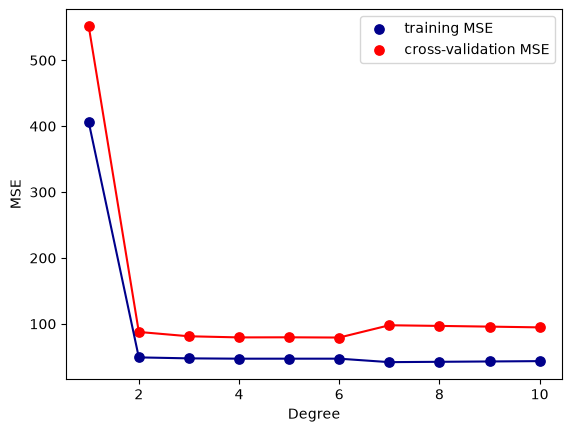

In [32]:
degrees = range(1,11)
plt.scatter(degrees, train_mses, c='darkblue', s=45, label='training MSE')
plt.scatter(degrees, cv_mses, c='red', s=45, label='cross-validation MSE')
plt.plot(degrees, cv_mses, c='red')
plt.plot(degrees, train_mses, c='darkblue')
plt.xlabel('Degree')
plt.ylabel('MSE')
plt.legend()
plt.show()

In [33]:
degree = np.argmin(cv_mses) + 1
print(f"lowest CV MSE is found in the model with degree = {degree}")

lowest CV MSE is found in the model with degree = 6


In [34]:
# add polynomial features to the test set
X_test_mapped = polys[degree-1].transform(x_test)

# scale the test set
X_test_mapped_scaled = scalers[degree-1].transform(X_test_mapped)

# compute the test MSE
yhat = models[degree-1].predict(X_test_mapped_scaled)
test_mse = mean_squared_error(y_test, yhat) / 2

print(f"Training MSE: {train_mses[degree-1]:.2f}")
print(f"Cross-validation MSE: {cv_mses[degree-1]:.2f}")
print(f"Test MSE: {test_mse:.2f}")

Training MSE: 47.15
Cross-validation MSE: 79.22
Test MSE: 101.50


In [35]:
x_new = np.linspace(np.min(x_train), np.max(x_train), 5000)
x_new = np.expand_dims(x_new, axis=1)
x_new.shape

(5000, 1)

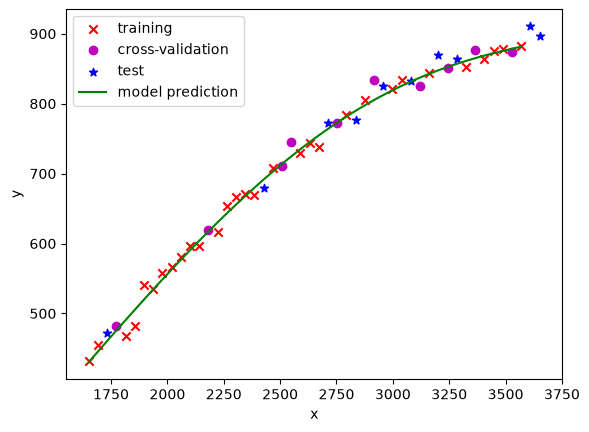

In [36]:
poly_sel = polys[5]
scaler_poly_sel = scalers[5]
model_sel = models[5]

x_new_mapped = poly_sel.transform(x_new)
x_new_mapped_scaled = scaler_poly_sel.transform(x_new_mapped)

yhat = model_sel.predict(x_new_mapped_scaled)

plt.scatter(x_train, y_train, marker='x', c='r', label='training')
plt.scatter(x_cv, y_cv, marker='o', c='m', label='cross-validation')
plt.scatter(x_test, y_test, marker='*', c='b', label='test')
plt.plot(x_new, yhat, c='g', label='model prediction')

plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

In [37]:
# as there is no need to add polynomial features because neural network can learn non-linear relations
# so we set degree to 1 as there is no need to do all of this
degree = 1
poly = PolynomialFeatures(degree, include_bias=False)
X_train_mapped = poly.fit_transform(x_train)
X_cv_mapped = poly.transform(x_cv)
X_test_mapped = poly.transform(x_test)

In [38]:
scaler = StandardScaler()
X_train_mapped_scaled = scaler.fit_transform(X_train_mapped)
X_cv_mapped_scaled = scaler.transform(X_cv_mapped)
X_test_mapped_scaled = scaler.transform(X_test_mapped)

In [39]:
from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Sequential
from tensorflow.keras.activations import relu, linear

In [40]:
def build_models():

    tf.random.set_seed(1)
    
    model_1 = Sequential(
        [
            # tf.keras.Input(shape=(1,)),
            Dense(25, activation='relu'),
            Dense(15, activation='relu'),
            Dense(1, activation='linear')
        ], name='model_1'
    )

    model_2 = Sequential(
        [
            # tf.keras.Input(shape=(1,)),
            Dense(20, activation='relu'),
            Dense(12, activation='relu'),
            Dense(12, activation='relu'),
            Dense(20, activation='relu'),
            Dense(1, activation='linear')
        ], name='model_2'
    )

    model_3 = Sequential(
        [
            # tf.keras.Input(shape=(1,)),
            Dense(32, activation='relu'),
            Dense(16, activation='relu'),
            Dense(8, activation='relu'),
            Dense(4, activation='relu'),
            Dense(12, activation='relu'),
            Dense(1, activation='linear')
        ], name='model_3'
    )

    return [model_1, model_2, model_3]

In [41]:
nn_train_mses = []
nn_cv_mses = []
nn_models = build_models()

for model in nn_models:
    
    model.compile(
        loss = 'mse',
        optimizer = tf.keras.optimizers.Adam(0.1)
    )

    print(f"Training {model.name} ...")

    model.fit(
        X_train_mapped_scaled, y_train,
        epochs=300,
        verbose=0
    )

    print("Done!\n")

    # Record the training MSE
    yhat = model.predict(X_train_mapped_scaled, verbose=0)
    train_mse = mean_squared_error(y_train, yhat) / 2
    nn_train_mses.append(train_mse)

    # Record the cross-validation MSE
    yhat = model.predict(X_cv_mapped_scaled, verbose=0)
    cv_mse = mean_squared_error(y_cv, yhat) / 2
    nn_cv_mses.append(cv_mse)

Training model_1 ...
Done!

Training model_2 ...
Done!

Training model_3 ...
Done!



In [42]:
print("RESULTS:")
for model_num in range(len(nn_train_mses)):
    print(f"Model {model_num+1}: Training MSE: {nn_train_mses[model_num]:.2f}, " + 
         f"CV MSE: {nn_cv_mses[model_num]:.2f}"
         )

RESULTS:
Model 1: Training MSE: 72.86, CV MSE: 101.45
Model 2: Training MSE: 73.71, CV MSE: 113.76
Model 3: Training MSE: 406.19, CV MSE: 551.78


In [43]:
# select the model with the lowest validation error
model_num = 3
yhat = nn_models[model_num-1].predict(X_test_mapped_scaled)
test_mse = mean_squared_error(y_test, yhat) / 2

print(f"Selected Model: {model_num}")
print(f"Training MSE: {nn_train_mses[model_num-1]:.2f}")
print(f"Cross Validation MSE: {nn_cv_mses[model_num-1]:.2f}")
print(f"Test MSE: {test_mse:.2f}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
Selected Model: 3
Training MSE: 406.19
Cross Validation MSE: 551.78
Test MSE: 467.26


In [44]:
# now we're going to the model selection and evaluation to the classification problem

In [45]:
data = np.loadtxt('data_w3_ex2.csv', delimiter=',')
x_bc = data[:, :-1]
y_bc = data[:, -1]

# convert y_bc to 2D (x_bc is already 2D)

y_bc = np.expand_dims(y_bc, axis=1)

print(f"x_bc.shape: {x_bc.shape}")
print(f"y_bc.shape: {y_bc.shape}")

x_bc.shape: (200, 2)
y_bc.shape: (200, 1)


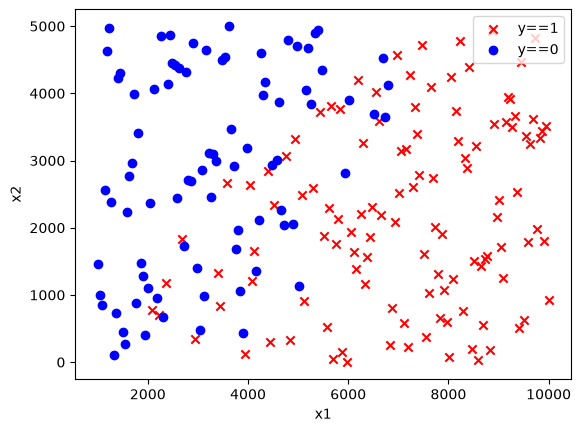

In [46]:
# plot the dataset
positive = y_bc.flatten() == 1
negative = y_bc.flatten() == 0
plt.scatter(x_bc[positive, 0], x_bc[positive,1], c='r', marker='x', label='y==1')
plt.scatter(x_bc[negative, 0], x_bc[negative,1], c='b', label='y==0')
plt.xlabel('x1')
plt.ylabel('x2')
plt.legend()
plt.show()

In [47]:
# split our dataset into training, validation, and test sets
x_bc_train, x_, y_bc_train, y_ = train_test_split(x_bc, y_bc, test_size=0.4, random_state=1)
x_bc_cv, x_bc_test, y_bc_cv, y_bc_test = train_test_split(x_, y_, test_size=0.5, random_state=1)

del x_, y_

print("x_bc_train.shape", x_bc_train.shape)
print("x_bc_cv.shape", x_bc_cv.shape)
print("x_bc_test.shape", x_bc_test.shape)
print("y_bc_train.shape", y_bc_train.shape)
print("y_bc_cv.shape", y_bc_cv.shape)
print("y_bc_test.shape", y_bc_test.shape)

x_bc_train.shape (120, 2)
x_bc_cv.shape (40, 2)
x_bc_test.shape (40, 2)
y_bc_train.shape (120, 1)
y_bc_cv.shape (40, 1)
y_bc_test.shape (40, 1)


In [48]:
scaler_linear = StandardScaler()

x_bc_train_scaled = scaler_linear.fit_transform(x_bc_train)
x_bc_cv_scaled = scaler_linear.transform(x_bc_cv)
x_bc_test_scaled = scaler_linear.transform(x_bc_test)


In [49]:
2/5

0.4

In [50]:
# sample model output
probabilities = np.array([0.2, 0.6, 0.7, 0.3, 0.8])

predictions = (probabilities >= 0.5).astype(int)

ground_truth = np.array([1, 1, 1, 1, 1])

misclassified = 0
num_predictions = len(predictions)

for i in range(num_predictions):
    if predictions[i] != ground_truth[i]:
        misclassified += 1
fraction_error = misclassified / num_predictions

print(f"probabilites: {probabilities}")
print(f"predictions: {predictions}")
print(f"targets: {ground_truth}")
print(f"fraction of misclassified data (for loop): {fraction_error}")
print(f"fraction of misclassified data (np.mean)): {np.mean(predictions != ground_truth)}")

probabilites: [0.2 0.6 0.7 0.3 0.8]
predictions: [0 1 1 0 1]
targets: [1 1 1 1 1]
fraction of misclassified data (for loop): 0.4
fraction of misclassified data (np.mean)): 0.4


In [51]:
arr = np.array([True, False, True, False, True])
np.mean(arr)

np.float64(0.6)

In [52]:
nn_train_error = []
nn_cv_error = []

models_bc = build_models()

for model in models_bc:

    model.compile(
        loss = tf.keras.losses.BinaryCrossentropy( from_logits=True ),
        optimizer = tf.keras.optimizers.Adam(learning_rate=0.01)
    )

    print(f"Training {model.name} ....")

    model.fit(
        x_bc_train_scaled, y_bc_train,
        epochs=200,
        verbose=0
    )

    print(f"Done!\n")

    threshold = 0.5

    # Record the fraction of misclassified examples for the training set
    yhat = model.predict(x_bc_train_scaled, verbose=0)
    yhat = tf.math.sigmoid(yhat)
    yhat = np.where(yhat >= threshold, 1, 0)
    train_error = np.mean(yhat != y_bc_train)
    nn_train_error.append(train_error)

    # Record the fraction of misclassified examples for the cross validation set
    yhat = model.predict(x_bc_cv_scaled, verbose=0)
    yhat = tf.math.sigmoid(yhat)
    yhat = np.where(yhat >= threshold, 1, 0)
    cv_error = np.mean(yhat != y_bc_cv)
    nn_cv_error.append(cv_error)

print("RESULTS!")
for model_num in range(len(nn_train_error)):
    print(
        f"Model {model_num+1}: ",
        f"Training Set Classification Error: {nn_train_error[model_num]:.5f},",
        f"CV Set Classification Error: {nn_cv_error[model_num]:.5f}"
    )

Training model_1 ....
Done!

Training model_2 ....
Done!

Training model_3 ....
Done!

RESULTS!
Model 1:  Training Set Classification Error: 0.02500, CV Set Classification Error: 0.12500
Model 2:  Training Set Classification Error: 0.05833, CV Set Classification Error: 0.15000
Model 3:  Training Set Classification Error: 0.11667, CV Set Classification Error: 0.15000


In [53]:
# select the model with the lowest cv error
model_num = 2

# compute the test error 
yhat = models_bc[model_num-1].predict(x_bc_test_scaled, verbose=0),
yhat = tf.math.sigmoid(yhat)
yhat = np.where(yhat >= threshold, 1, 0)
test_error = np.mean(yhat != y_bc_test)

print(f"Selected model: {model_num}")
print(f"Training Set Classification Error: {nn_train_error[model_num-1]}")
print(f"CV Set Classification Error: {nn_cv_error[model_num-1]}")
print(f"Test Set Classification Error: {test_error}")

Selected model: 2
Training Set Classification Error: 0.058333333333333334
CV Set Classification Error: 0.15
Test Set Classification Error: 0.2
